| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_2_Root_finding.ipynb) | [⏩](../6_ANALISIS_NUMERICO/6_4_Integracion_numerica.ipynb) |

# 6.3 Interpolación: reconstruir una función a partir de muestras

Una sonda registra temperatura cada minuto; un simulador de fluidos entrega valores en una malla; una red neuronal necesita datos en otro conjunto de puntos. **Interpolar** significa construir una función que reproduzca exactamente las muestras y permita evaluar valores entre ellas.

Objetivos: derivar interpolación lineal y polinómica, observar el fenómeno de Runge, comparar splines con métodos que conservan la forma y separar error de interpolación, ruido y extrapolación. Se requiere conocer funciones, polinomios y errores numéricos. Ejecuta las celdas de arriba abajo: todos los datos se generan aquí y no hacen falta descargas.

## 1. Planteamiento y vocabulario

Dados nodos distintos $x_0,\ldots,x_n$ y valores $y_i=f(x_i)$, buscamos $p(x_i)=y_i$. La función $f$ puede ser desconocida: tener datos no equivale a conocer su comportamiento entre nodos. Llamamos **interpolación** a evaluar dentro del intervalo de muestras y **extrapolación** a evaluar fuera.

Una regresión permite residuos en los puntos observados para aprender una tendencia. La interpolación exacta obliga a pasar por todos, incluido su ruido. Tampoco es una predicción temporal por sí sola: interpolar temperaturas históricas no aporta una ley física de evolución. Si los datos son ruidosos, necesitarás regularización o un modelo probabilístico.

En los ejemplos conocemos $f$ únicamente para poder medir el error. En una aplicación real se reserva una malla de validación, se compara con medidas adicionales o se emplean cotas basadas en regularidad.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate, integrate
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True,
                     "font.size": 11})
np.set_printoptions(precision=5, suppress=True)

## 2. Interpolación lineal y pesos

Entre dos nodos $x_i<x<x_{i+1}$, la recta es
$$p(x)=y_i\frac{x_{i+1}-x}{h_i}+y_{i+1}\frac{x-x_i}{h_i},\qquad h_i=x_{i+1}-x_i.$$
Los pesos suman uno y son no negativos dentro del intervalo. Por ello el resultado queda entre ambos valores y preserva positividad local. Con $f\in C^2$,
$$f(x)-p(x)=\frac{f''(\xi)}{2}(x-x_i)(x-x_{i+1}),$$
y $|f-p|\le h_i^2\max|f''|/8$. El error de valores es de segundo orden; la derivada del interpolante tiene saltos en los nodos. Este detalle importa cuando una pérdida SciML utiliza derivadas.

Error máximo: 0.03291453728293925


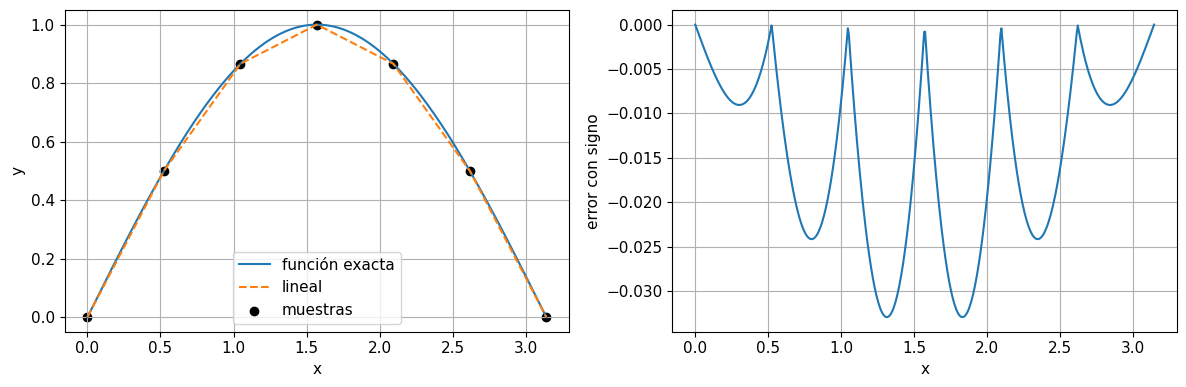

In [2]:
x = np.linspace(0, np.pi, 7)
y = np.sin(x)
q = np.linspace(0, np.pi, 500)
linear = np.interp(q, x, y)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(q, np.sin(q), label="función exacta")
ax[0].plot(q, linear, "--", label="lineal")
ax[0].scatter(x, y, color="black", label="muestras")
ax[1].plot(q, linear - np.sin(q))
ax[0].legend(); ax[0].set(xlabel="x", ylabel="y")
ax[1].set(xlabel="x", ylabel="error con signo")
plt.tight_layout(); plt.show()
print("Error máximo:", np.max(np.abs(linear - np.sin(q))))

**Cómo interpretar el resultado.** Las rectas coinciden con los datos, mientras que el error aparece entre ellos. El seno es cóncavo en este dominio y las cuerdas quedan por debajo: la curva del error debe ser mayormente negativa. Los ceros del error en los nodos no prueban exactitud en todo el intervalo.

## 3. Polinomio de Lagrange

Existe un único polinomio de grado a lo sumo $n$ que pasa por $n+1$ nodos distintos:
$$p_n(x)=\sum_{i=0}^n y_i L_i(x),\quad
L_i(x)=\prod_{j\ne i}\frac{x-x_j}{x_i-x_j}.$$
La identidad $L_i(x_j)=\delta_{ij}$ explica por qué funciona. Para tres nodos $0,1,2$ y valores $1,2,5$, resulta $p_2(x)=1+x^2$. No hace falta resolver un sistema: las bases ya están adaptadas a las condiciones.

También podemos resolver un sistema de Vandermonde con columnas $1,x,x^2,\ldots$. Para grados altos, esa base puede estar mal condicionada. **El problema de interpolar** y **la fórmula empleada para evaluarlo** tienen riesgos distintos. La forma baricéntrica evalúa el mismo polinomio con mejor comportamiento numérico que expandir todos sus coeficientes.

In [3]:
nodes = np.array([0., 1., 2.])
values = np.array([1., 2., 5.])
poly = interpolate.BarycentricInterpolator(nodes, values)
test = np.array([0.25, 0.5, 1.5])
print("Interpolación:", poly(test))
print("1 + x²:", 1 + test**2)
print("Residuo en nodos:", np.max(np.abs(poly(nodes)-values)))

Interpolación: [1.0625 1.25   3.25  ]
1 + x²: [1.0625 1.25   3.25  ]
Residuo en nodos: 0.0


**Cómo interpretar el resultado.** Los valores coinciden con el polinomio conocido, incluido fuera de los nodos. Este ejemplo verifica la implementación; el éxito para un polinomio cuadrático no implica estabilidad de grados arbitrariamente grandes.

## 4. Error polinómico y fenómeno de Runge

Si $f\in C^{n+1}$,
$$f(x)-p_n(x)=\frac{f^{(n+1)}(\xi_x)}{(n+1)!}\prod_{i=0}^n(x-x_i).$$
Aumentar $n$ altera la derivada y el producto: el error no necesariamente disminuye con nodos equidistantes. Para $f(x)=1/(1+25x^2)$ aparecen oscilaciones cerca de los extremos. Los nodos de Chebyshev
$$x_j=\cos\left(\frac{(2j+1)\pi}{2(n+1)}\right),\quad j=0,\ldots,n,$$
se concentran en los extremos y reducen la amplificación asociada al producto nodal. El experimento compara **el mismo grado y la misma función**, cambiando solo los nodos.

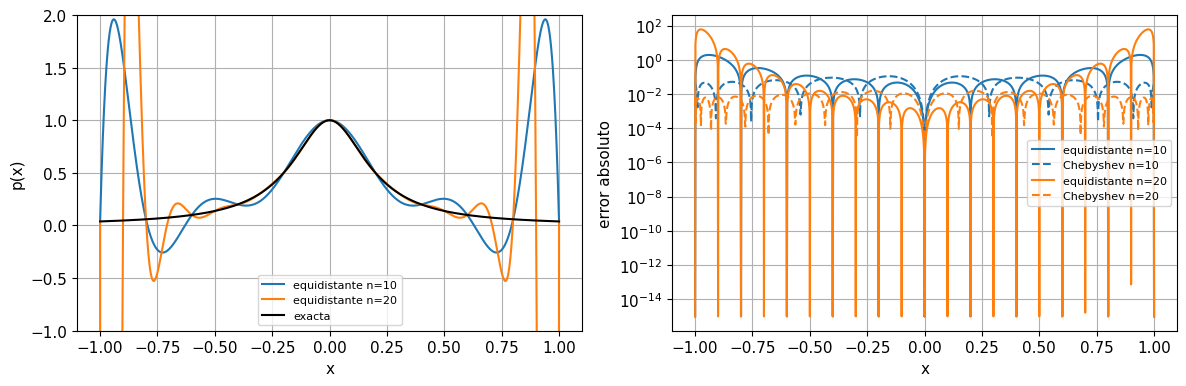

In [4]:
runge = lambda z: 1 / (1 + 25*z*z)
q = np.linspace(-1, 1, 1501)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, color in [(10, "tab:blue"), (20, "tab:orange")]:
    xe = np.linspace(-1, 1, n+1)
    xc = np.sort(np.cos((2*np.arange(n+1)+1)*np.pi/(2*(n+1))))
    pe = interpolate.BarycentricInterpolator(xe, runge(xe))(q)
    pc = interpolate.BarycentricInterpolator(xc, runge(xc))(q)
    ax[0].plot(q, pe, color=color, label=f"equidistante n={n}")
    ax[1].semilogy(q, np.maximum(abs(pe-runge(q)), 1e-15), color=color,
                   label=f"equidistante n={n}")
    ax[1].semilogy(q, np.maximum(abs(pc-runge(q)), 1e-15), "--",
                   color=color, label=f"Chebyshev n={n}")
ax[0].plot(q, runge(q), "k", label="exacta")
ax[0].set(ylim=(-1, 2), xlabel="x", ylabel="p(x)")
ax[1].set(xlabel="x", ylabel="error absoluto")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cómo interpretar el resultado.** La figura izquierda limita el eje vertical para hacer visible la solución; algunas oscilaciones pueden salir del encuadre. La figura derecha muestra el error sin esconderlo. Los nodos de Chebyshev suelen mejorar esta función, pero no corrigen falta de regularidad ni datos ruidosos.

## 5. Splines cúbicos y condiciones de frontera

Un spline cúbico utiliza un polinomio de grado tres en cada subintervalo. Se exigen continuidad de $s$, $s'$ y $s''$ en nodos internos. Faltan dos condiciones: un spline **natural** usa $s''(a)=s''(b)=0$, uno **clamped** prescribe $s'(a)$ y $s'(b)$, y `CubicSpline` usa por defecto condiciones `not-a-knot`.

Estas alternativas representan información adicional; no son meras opciones estéticas. Para una función periódica se deben compatibilizar los valores de los extremos y puede usarse `bc_type="periodic"`. El orden típico en valores es $O(h^4)$ bajo regularidad y condiciones de frontera compatibles; no supongas esa tasa automáticamente para cualquier cierre de borde.

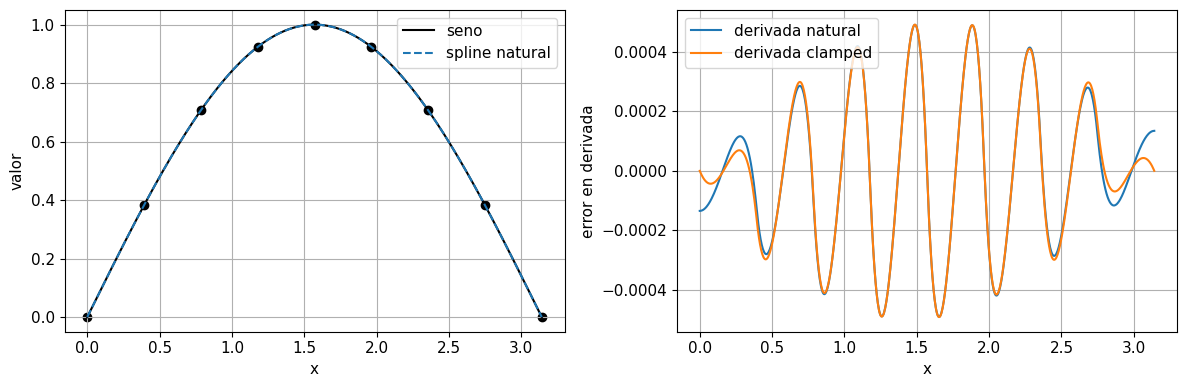

In [5]:
x = np.linspace(0, np.pi, 9); y = np.sin(x)
q = np.linspace(0, np.pi, 800)
natural = interpolate.CubicSpline(x, y, bc_type="natural")
clamped = interpolate.CubicSpline(x, y, bc_type=((1, 1.), (1, -1.)))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(q, np.sin(q), "k", label="seno")
ax[0].plot(q, natural(q), "--", label="spline natural")
ax[0].scatter(x, y, color="black")
ax[1].plot(q, natural(q, 1)-np.cos(q), label="derivada natural")
ax[1].plot(q, clamped(q, 1)-np.cos(q), label="derivada clamped")
ax[0].set(xlabel="x", ylabel="valor"); ax[1].set(xlabel="x", ylabel="error en derivada")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

**Cómo interpretar el resultado.** Las curvas de valores casi se superponen; estudiar las derivadas revela diferencias. Aquí las segundas derivadas del seno son cero en ambos extremos, por lo que la condición natural es compatible. `clamped` utiliza información exacta sobre pendientes que quizá no estaría disponible en datos reales.

## 6. Preservar monotonía con PCHIP

Un spline suave puede superar el rango de valores observados. Si los datos representan concentración no negativa, población o una función acumulada, ese sobrepaso puede ser físicamente inadmisible. PCHIP construye cúbicas de Hermite con pendientes elegidas para preservar la forma y la monotonía de datos monotónicos.

PCHIP es $C^1$: su segunda derivada puede saltar. Un spline cúbico es $C^2$ pero puede oscilar. La decisión depende de qué propiedades necesita el modelo. Una pérdida con $u_{xx}$ necesita una discusión adicional si se usa un interpolante solo $C^1$.

Mínimo spline: -0.056136992878281965 Mínimo PCHIP: 0.0
¿PCHIP monotónico? True


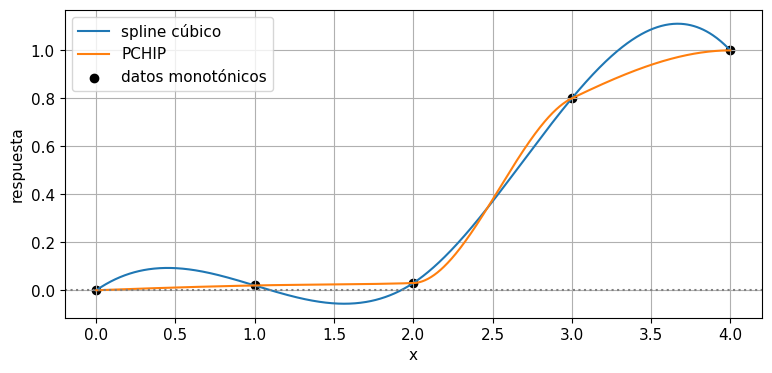

In [6]:
x = np.array([0., 1., 2., 3., 4.])
y = np.array([0., 0.02, 0.03, 0.8, 1.])
q = np.linspace(0, 4, 800)
spline = interpolate.CubicSpline(x, y)
pchip = interpolate.PchipInterpolator(x, y)
plt.plot(q, spline(q), label="spline cúbico")
plt.plot(q, pchip(q), label="PCHIP")
plt.scatter(x, y, color="black", label="datos monotónicos")
plt.axhline(0, color="gray", linestyle=":")
plt.xlabel("x"); plt.ylabel("respuesta"); plt.legend(); plt.show()
print("Mínimo spline:", spline(q).min(), "Mínimo PCHIP:", pchip(q).min())
print("¿PCHIP monotónico?", np.all(np.diff(pchip(q)) >= -1e-12))

**Cómo interpretar el resultado.** El spline puede producir valores negativos o retrocesos entre datos crecientes. PCHIP conserva la monotonía en este caso. Medir los mínimos y las diferencias consecutivas es más informativo que juzgar únicamente la suavidad visual.

## 7. Comprobar convergencia

Una tasa observada se estima con
$$p_{\rm obs}=\log_2\left(\frac{E(h)}{E(h/2)}\right).$$
Para interpolación lineal de una función suave se espera aproximadamente $p=2$. Evaluamos el error máximo en una malla densa que no coincide con los nodos. Si solo midiéramos en los nodos, todas las interpolaciones exactas darían cero y el estudio sería inútil.

El orden observado puede diferir en mallas gruesas o al alcanzar precisión de máquina. Debe interpretarse como evidencia numérica en un régimen concreto, no como demostración general.

Órdenes observados: [1.97555 1.99399 1.99849 2.00036]


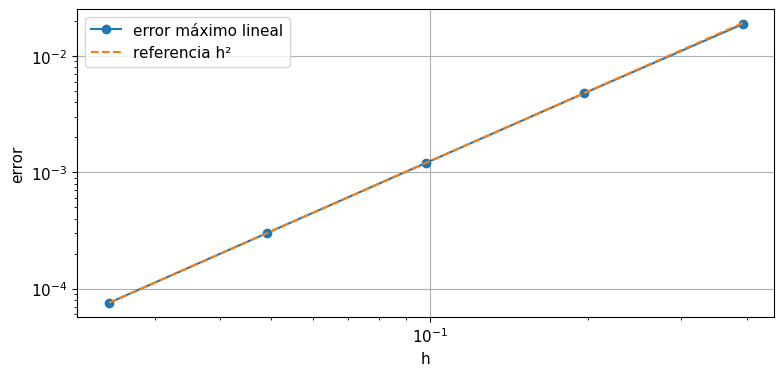

In [7]:
ns = np.array([8, 16, 32, 64, 128])
q = np.linspace(0, np.pi, 4001)
errors = []
for n in ns:
    x = np.linspace(0, np.pi, n+1)
    errors.append(np.max(abs(np.interp(q, x, np.sin(x))-np.sin(q))))
errors = np.array(errors); hs = np.pi/ns
print("Órdenes observados:", np.log2(errors[:-1]/errors[1:]))
plt.loglog(hs, errors, "o-", label="error máximo lineal")
plt.loglog(hs, errors[-1]*(hs/hs[-1])**2, "--", label="referencia h²")
plt.xlabel("h"); plt.ylabel("error"); plt.legend(); plt.show()

**Cómo interpretar el resultado.** Los puntos deben seguir una pendiente cercana a dos. La malla de evaluación también es finita, por lo que se estima el máximo; aumentarla permite comprobar que el diagnóstico no depende de haber omitido el lugar del error máximo.

## 8. Ruido, suavizado y extrapolación

Con observaciones $y_i=f(x_i)+\varepsilon_i$, pasar exactamente por todos los puntos también reproduce $\varepsilon_i$. Un spline suavizado plantea un compromiso entre ajuste y rugosidad, asociado a un objetivo como
$$\sum_i (y_i-s(x_i))^2+\lambda\int (s''(x))^2\,dx.$$
La selección de $\lambda$ requiere validación o un modelo de ruido. No se debe escoger solo para que la gráfica resulte bonita. Fuera del dominio, un polinomio puede crecer rápidamente y un spline continúa su último segmento; ninguna de estas acciones añade evidencia física.

`np.interp` devuelve los valores extremos fuera del intervalo por defecto. `CubicSpline` puede extrapolar polinómicamente. Si una operación debe estar restringida al dominio observado, usa `extrapolate=False` y maneja explícitamente los valores `NaN`.

## 9. Interpolación en SciML

Al comparar una solución numérica $u(x,t)$ con sensores en posiciones distintas, primero se define un operador de observación $H$: $y\approx H(u)$. La interpolación forma parte de $H$ y su error puede confundirse con un error del modelo físico. Si el simulador devuelve una malla gruesa y el sensor observa un frente estrecho, entrenar más tiempo una red no recupera automáticamente la información perdida.

En un operador neuronal que transforma campos de entrada en campos de salida, cambiar resolución implica representar campos en mallas diferentes. Conviene comparar en una malla común y verificar transferencia de resolución. La interpolación de valores no garantiza conservación de masa: para densidades por celda se necesita un remapeo conservativo. Para coordenadas espaciales múltiples existen interpolantes de malla regular y de datos dispersos; un método 1D no debe aplicarse sobre arreglos aplanados ignorando la geometría.

## 10. Errores frecuentes y protocolo de trabajo

Ordena los nodos y verifica que no estén repetidos. Dos observaciones diferentes en el mismo nodo no definen una interpolación ordinaria; hay que reconciliarlas o formular un ajuste. Comprueba unidades de $x$ y $y$: grados Celsius y kelvin tienen las mismas diferencias, pero distintas referencias absolutas.

Antes de elegir el método, pregunta si importan positividad, monotonía, periodicidad, derivadas o conservación. Después revisa el error entre nodos, prueba una malla más fina y separa interior y extremos. Guarda el intervalo válido junto con el interpolante. Para datos ruidosos, reserva observaciones independientes. Una curva que pasa por todos los puntos de entrenamiento no ha demostrado capacidad de generalizar.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../6_ANALISIS_NUMERICO/6_2_Root_finding.ipynb) | [⏩](../6_ANALISIS_NUMERICO/6_4_Integracion_numerica.ipynb) |